# Right Censoring

Consider all patients, even those who do not have clinical endpoints.

In [1]:
import os
import re
import sys
import pickle
import numpy as np
import pandas as pd
import scipy as sc
from scipy.stats import linregress, pearsonr, spearmanr, kendalltau, t
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from lmfit import minimize, Parameters
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (test_progression, TruncateDataframe, ExtractTreatmentFromDf, LoadPatientData, calc_critical_treatment_threshold, GetPatientIDs,
                     calc_average_overshoot, calc_delta_benefit, predict_ct_ttp)
from fittingUtils import residual, compute_r_sq, load_fit, generate_fitSummaryDf
from plotUtils import PlotDrug, PlotData, convert_to_rgb_grayscale, redistribute_rgb
from odeModels import LotkaVolterraModel

In [2]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

In [3]:
file_path = os.path.dirname(os.path.abspath("__file__"))
out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Trunc_fits")

RERUN_FITTING = True

In [4]:
def SimulateFit(fit_params, dataDf, dt=1, solver_kws={}):
    myModel = LotkaVolterraModel()
    myModel.SetParams(**fit_params)
    myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
    # Interpolate to the desired time grid
    t_eval = np.arange(0, myModel.resultsDf.Time.max(), dt)
    trimmedResultsDic = {'Time': t_eval}
    for variable in ['S', 'R', 'TumourSize', 'DrugConcentration']:
        f = sc.interpolate.interp1d(myModel.resultsDf.Time, myModel.resultsDf[variable])
        trimmedResultsDic = {**trimmedResultsDic, variable: f(t_eval)}
    myModel.resultsDf = pd.DataFrame(trimmedResultsDic)
    return myModel

In [5]:
def Plot_method(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_color = 'k', colors = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    linestyles = ['-', (0, (10,10)), (0, (5,5))]
    for i, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df['Time'], df[var], linewidth=linewidth, linestyle=linestyles[i], color=colors[var], **kwargs)

    PlotDrug(df, ax, drug_color, plotDrugAsBar = True, currDrugBarPosition = 1.25)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)

## Patient Datasets

Loaded Patient IDs: [1, 2, 3, 4, 6, 11, 12, 13, 14, 15, 16, 17, 19, 20, 22, 24, 25, 26, 28, 29, 30, 31, 32, 36, 37, 39, 40, 41, 42, 44, 46, 50, 51, 52, 54, 55, 56, 58, 60, 61, 62, 63, 64, 66, 71, 75, 77, 78, 79, 81, 83, 84, 85, 86, 87, 88, 91, 92, 93, 94, 95, 96, 97, 99, 100, 101, 102, 104, 105, 106, 108, 109]


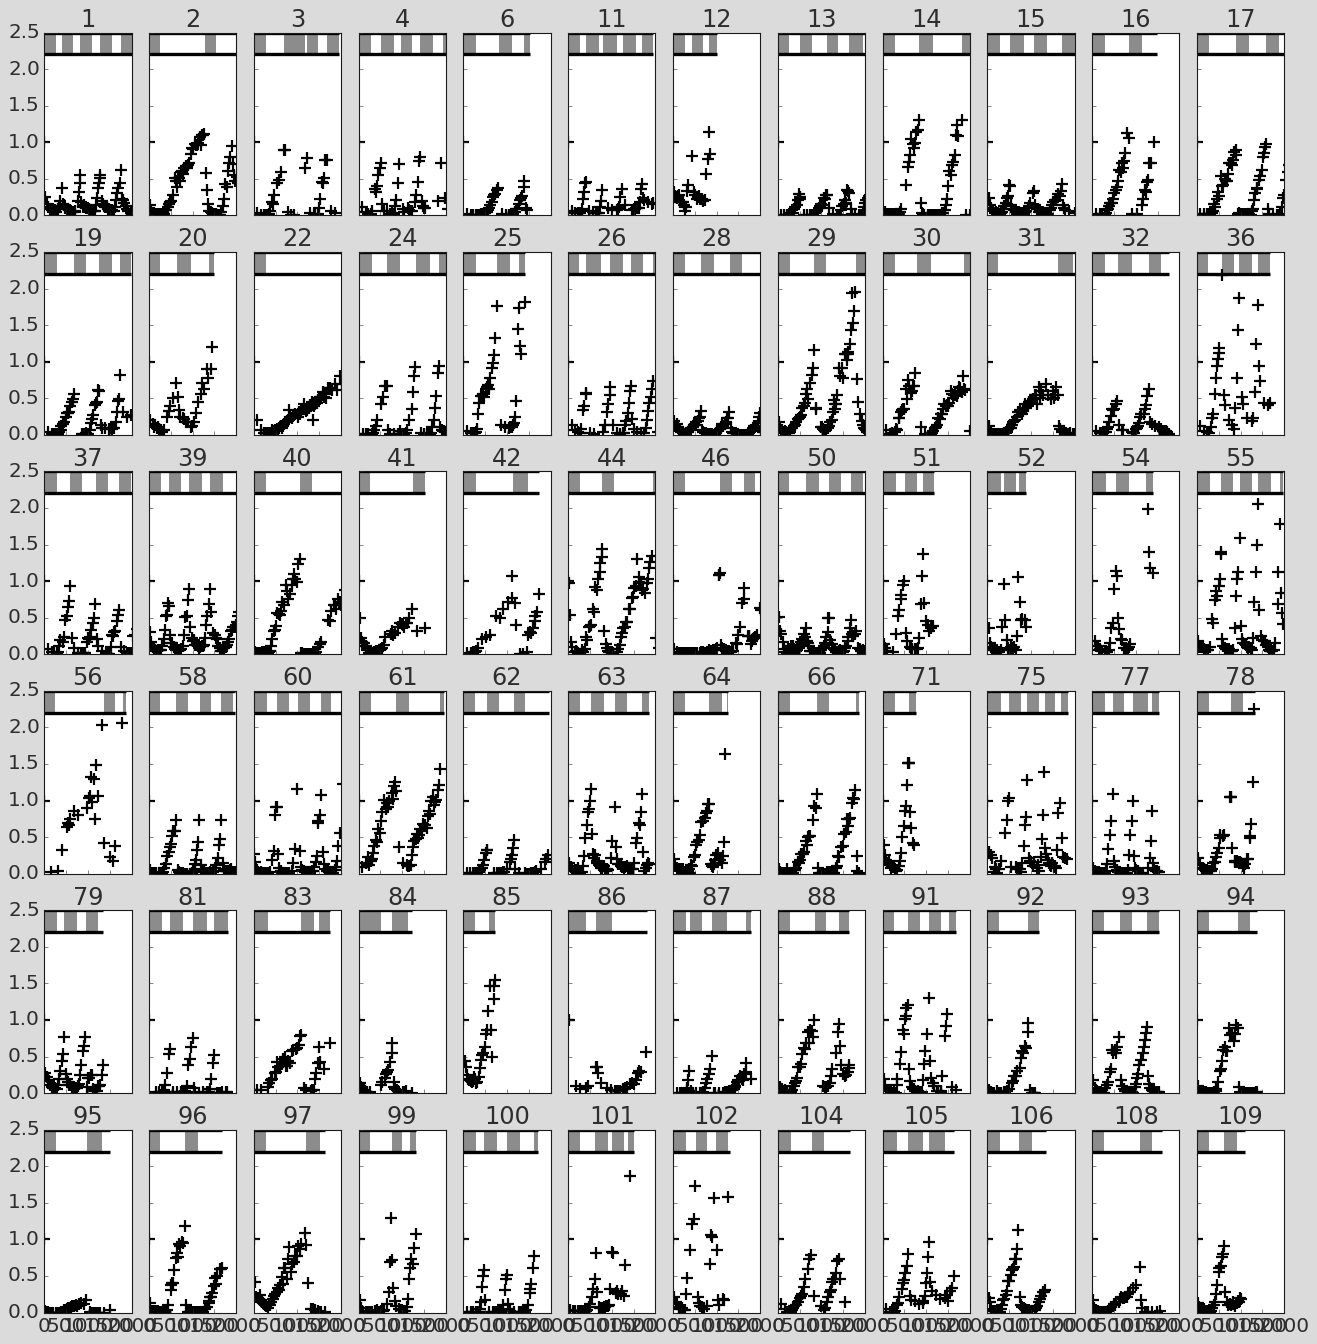

In [6]:
data_path = "../patients/Bruchovsky_et_al/Complete_data"
patientIds = GetPatientIDs(data_path)
print("Loaded Patient IDs: " + str(patientIds))
# patientIds = patientIds[:-2]  # Exclude two trickiest patients

plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(6, int((len(patientIds)+5)/6), figsize=(20, 20), sharey=True, sharex=True)
for i, patientId in enumerate(patientIds):
    dataDf = LoadPatientData(patientId, data_path)
    PlotData(dataDf, axs.flatten()[i], drugBarPosition=2.2,
             drugBarHeight=0.3)
    axs.flatten()[i].set_title(patientId)
    axs.flatten()[i].set_ylim(0, 2.5)
if len(patientIds) % 2 == 1: axs.flatten()[-1].axis('off');

## Fit to first cycle only

These parameter values can then subsequently be used for validation later.

In [7]:
out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Trunc_fits")

patientsToAnalyseList = patientIds
solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

# New
params.add('turnover', min=0.01, max=1., vary=True)
params.add('K', value=3, min=2.5, max=5, vary=True)

# Fixed from historical data/estimates
params.add('fR', value=1e-5, vary=False)
params.add('cost', value=0.1, vary=False)
params.add('rS', value=0.027, vary=False)
params.add('n0', value=0.1, vary=False)  # Will be matched to initial value

# Fixed/Calculated Parameters
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [8]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseList):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index()

        last_cycle1_index = training_data_df[training_data_df['CycleId'] == 1].index[-1]
        
        training_data_df = training_data_df[:last_cycle1_index+2]
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

100%|██████████| 72/72 [01:31<00:00,  1.27s/it]


In [9]:
# Store patient parameters in a dataframe
if RERUN_FITTING:
    trunc_df = pd.DataFrame()
    for patient_dir in os.listdir(os.path.join(out_dir, model_name)):
        fitSummaryDf = generate_fitSummaryDf(os.path.join(out_dir, model_name, patient_dir))
        fitSummaryDf.insert(0, "PatientId",  int(re.findall(r'\d+', patient_dir)[0]))
        trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
        
    trunc_df['TimeInTrial'] = trunc_df['PatientId'].apply(lambda x: \
        LoadPatientData(x, data_path).Time.max())
    trunc_df = trunc_df.sort_values(by="PatientId").reset_index()
    trunc_df = trunc_df[trunc_df['PatientId'].isin(patientIds)]
    trunc_df['Cost'] = 1 - trunc_df['rR'] / trunc_df['rS']; 
    trunc_df['Turnover'] = trunc_df['dS'] / trunc_df['rS']
    trunc_df['K'] = 2.5

    #Test progression
    trunc_df['Progression'] = trunc_df.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d"%(trunc_df.Progression.sum(), len(trunc_df)), end='')
    print(f"  ({[x for x in trunc_df.PatientId[trunc_df.Progression==True]]})")

    
    # Save patient params
    trunc_df.to_csv("patient_fits/first_cycle_params_all.csv", index=False)
else:
    trunc_df = pd.read_csv("patient_fits/first_cycle_params_all.csv")

Progression: 57/72  ([1, 3, 4, 11, 12, 13, 14, 15, 16, 17, 19, 20, 24, 25, 26, 28, 29, 30, 32, 36, 37, 39, 40, 44, 50, 51, 52, 54, 55, 58, 60, 61, 62, 63, 64, 66, 71, 75, 77, 78, 79, 81, 84, 85, 86, 88, 91, 93, 96, 99, 100, 101, 102, 104, 105, 106, 109])


## Clinical Outcomes

In [353]:
data_path = "../patients/Bruchovsky_et_al/Complete_data"
def get_ttp(patientId, **kwargs):
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['PSA'] < 1.2 * dataDf['PSA'].iloc[0]]
    return dataDf['Time'].iloc[-1]


In [354]:
def get_N_star(patientId, **kwargs):
    ttp = get_ttp(patientId, **kwargs)
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['Time'] <= ttp]

    N_star = dataDf['PSA'].mean()
    interval = dataDf['Time'].diff().mean()
    overshoot = calc_average_overshoot(int(interval), N_star, **kwargs)
    return N_star + overshoot

def predict_at_threshold_ttp(n_crit, **kwargs):
    params = kwargs
    benefit = calc_delta_benefit(kappa=n_crit / params['K'], **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

def calc_AT_score(patientId, **kwargs):
    params = kwargs
    n_crit = get_N_star(patientId, **params)
    return calc_delta_benefit(kappa=n_crit / params['K'], **params)

In [355]:
def predict_ct_ttp(n_lim=None, **kwargs):
    # This is in the absence of sensitive cells
    params = kwargs
    if n_lim is None: n_lim = params['n0'] * 1.2
    
    factor = params['rR'] - params['dR']
    log_num = params['rR'] - factor * (params['K'] / params['R0'])
    log_den = params['rR'] - factor * (params['K'] / n_lim)
    return np.log(log_num / log_den) / factor

In [356]:
# Generate a table with patient id, predicted AT TTP
TTP_data = []
param_sets = [trunc_df]

patientIds = [x for x in patientIds if x in trunc_df.PatientId[trunc_df.Progression==True].values]


for patientId in tqdm(patientIds):
    param_set = trunc_df.loc[trunc_df.PatientId == patientId].iloc[0].to_dict()
    
    try:
        ct_perfect_preds = int(predict_ct_ttp(**param_set))
        at_scores = calc_AT_score(patientId, **param_set)
        clinical_preds = int(predict_at_threshold_ttp(param_set['n0'] * get_N_star(patientId, **param_set), **param_set))
        clinical_ttps = int(get_ttp(patientId))
        
        TTP_data.append([patientId, trunc_df.loc[trunc_df.PatientId == patientId].iloc[0]['RSquared'],
                         ct_perfect_preds, at_scores, clinical_preds, clinical_ttps])
    except Exception as e:
        # print(f"**Error processing patient {patientId}: {e}")
        continue

at_ttp_df = pd.DataFrame(TTP_data, columns=['PatientId', 'RSquared', 'CT_Perfect', 'AT_Score', 'Clinical_Preds', 'Clinical_TTP'])

ids_that_progress = at_ttp_df[at_ttp_df['CT_Perfect'] > 0]['PatientId']
at_ttp_df  = at_ttp_df[at_ttp_df['PatientId'].isin(ids_that_progress)]

# print(at_ttp_df)

100%|██████████| 57/57 [00:00<00:00, 135.08it/s]


In [426]:
# Filtering to patients with good fits (R^2 > 0.5)
poor_fit_patients = at_ttp_df[at_ttp_df['RSquared'] <= 0.5]['PatientId']
at_ttp_df = at_ttp_df[at_ttp_df['RSquared'] > 0.5]

In [427]:

# Linear regression
slope, intercept, r_value, p_value_linear, std_err = linregress(
    at_ttp_df['AT_Score'], at_ttp_df['Clinical_TTP']
)
print(f"Number of patients included in analysis: {len(at_ttp_df)}")

# slope uncertainty = standard error from linregress
print("Linear Regression:")
print(f"  R² = {r_value**2:.4f}")
print(f"  p-value = {p_value_linear:.4f}")


Number of patients included in analysis: 40
Linear Regression:
  R² = 0.0835
  p-value = 0.0706


In [428]:
from lifelines.statistics import logrank_test

progress_ids = set(pd.Series(ids_that_progress).astype(int).tolist())
other_ids = [pid for pid in GetPatientIDs(data_path) if pid not in progress_ids]
print(other_ids)

def _clinical_ttp(pid):
    return get_ttp(pid)

comparison_rows = []
for pid in GetPatientIDs(data_path):
    ttp = _clinical_ttp(pid)
    comparison_rows.append({
        "PatientId": pid,
        "Group": "ids_that_progress" if pid in progress_ids else "not_in_ids_that_progress",
        "Clinical_TTP": ttp,
    })

comparison_df = pd.DataFrame(comparison_rows)

summary = comparison_df.groupby("Group")["Clinical_TTP"].agg(
    N="count",
    Median_TTP="median",
    Q1_TTP=lambda x: x.quantile(0.25),
    Q3_TTP=lambda x: x.quantile(0.75),
)
summary["IQR_TTP"] = summary["Q3_TTP"] - summary["Q1_TTP"]

print("Observed Clinical_TTP by group:")
print(summary[["N", "Median_TTP", "Q1_TTP", "Q3_TTP", "IQR_TTP"]].round(2).to_string())

g1 = comparison_df[comparison_df["Group"] == "ids_that_progress"].copy()
g2 = comparison_df[comparison_df["Group"] == "not_in_ids_that_progress"].copy()

if len(g1) > 0 and len(g2) > 0:
    lr = logrank_test(
        g1["Clinical_TTP"],
        g2["Clinical_TTP"],
    )
    print(f"\nLog-rank test: chi2 = {lr.test_statistic:.4f}, p = {lr.p_value:.4g}")
else:
    print("\nLog-rank test not run: one group is empty.")


[2, 6, 22, 31, 41, 42, 46, 56, 83, 87, 92, 94, 95, 97, 108]
Observed Clinical_TTP by group:
                           N  Median_TTP  Q1_TTP  Q3_TTP  IQR_TTP
Group                                                            
ids_that_progress         57      1785.0  1351.0  2072.0    721.0
not_in_ids_that_progress  15      1631.0  1510.0  1916.0    406.0

Log-rank test: chi2 = 0.0048, p = 0.9449


In [429]:
# Compare poor-fit patients vs retained (good-fit) patients using the same summary + log-rank stats

poor_ids = set(pd.Series(poor_fit_patients).astype(int).tolist())
retained_ids = set(pd.Series(at_ttp_df["PatientId"]).astype(int).tolist())


comparison_rows = []
for pid in sorted(poor_ids | retained_ids):
    comparison_rows.append({
        "PatientId": pid,
        "Group": "poor_fit_patients" if pid in poor_ids else "retained_at_ttp_df",
        "Clinical_TTP": float(get_ttp(pid)),
    })

comparison_df_pf = pd.DataFrame(comparison_rows)

summary_pf = comparison_df_pf.groupby("Group")["Clinical_TTP"].agg(
    N="count",
    Median_TTP="median",
    Q1_TTP=lambda x: x.quantile(0.25),
    Q3_TTP=lambda x: x.quantile(0.75),
)
summary_pf["IQR_TTP"] = summary_pf["Q3_TTP"] - summary_pf["Q1_TTP"]

print("Clinical_TTP by group (poor-fit vs retained):")
print(summary_pf[["N", "Median_TTP", "Q1_TTP", "Q3_TTP"]].round(2).to_string())

g_poor = comparison_df_pf[comparison_df_pf["Group"] == "poor_fit_patients"]
g_keep = comparison_df_pf[comparison_df_pf["Group"] == "retained_at_ttp_df"]

if len(g_poor) > 0 and len(g_keep) > 0:
    lr_pf = logrank_test(
        g_poor["Clinical_TTP"],
        g_keep["Clinical_TTP"],
    )
    print(f"\nLog-rank test: chi2 = {lr_pf.test_statistic:.4f}, p = {lr_pf.p_value:.4g}")
else:
    print("\nLog-rank test not run: one group is empty.")

Clinical_TTP by group (poor-fit vs retained):
                     N  Median_TTP  Q1_TTP  Q3_TTP
Group                                             
retained_at_ttp_df  40      1897.5  1402.0  2086.0

Log-rank test not run: one group is empty.


In [430]:
excluded_ids = other_ids + list(poor_fit_patients)
included_ds = [pid for pid in GetPatientIDs(data_path) if pid not in excluded_ids]

# De-duplicate IDs
excluded_ids = sorted(set(excluded_ids))
included_ds = sorted(set(included_ds))

def biochemical_progression_status(patientId, **kwargs):
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    return dataDf['PSA'].max() > 1.2 * dataDf['PSA'].iloc[0]

def _mean_ci95(x):
    x = pd.Series(x).dropna().astype(float)
    n = len(x)
    mean = x.mean() if n > 0 else np.nan
    sd = x.std(ddof=1) if n > 1 else np.nan
    sem = sd / np.sqrt(n) if n > 1 else np.nan
    if n > 1:
        ci_half = t.ppf(0.975, df=n - 1) * sem
        lo, hi = mean - ci_half, mean + ci_half
    else:
        lo, hi = np.nan, np.nan
    return pd.Series({"N": n, "Mean_TTP": mean, "CI95_L": lo, "CI95_U": hi})

# Build group-level clinical TTP + event table
rows = []
for pid in included_ds:
    rows.append({
        "PatientId": pid,
        "Group": "included_ds",
        "Clinical_TTP": float(get_ttp(pid)),
        "Event": int(biochemical_progression_status(pid)),
    })

for pid in excluded_ids:
    rows.append({
        "PatientId": pid,
        "Group": "excluded_ids",
        "Clinical_TTP": float(get_ttp(pid)),
        "Event": int(biochemical_progression_status(pid)),
    })

comparison_df_22 = pd.DataFrame(rows)

summary_22 = comparison_df_22.groupby("Group")["Clinical_TTP"].apply(_mean_ci95).unstack()
print("Clinical_TTP mean and 95% CI by group:")
print(summary_22.round(2).to_string())

g_in = comparison_df_22[comparison_df_22["Group"] == "included_ds"]
g_ex = comparison_df_22[comparison_df_22["Group"] == "excluded_ids"]

if len(g_in) > 0 and len(g_ex) > 0:
    lr_22 = logrank_test(
        g_in["Clinical_TTP"],
        g_ex["Clinical_TTP"],
        event_observed_A=g_in["Event"],
        event_observed_B=g_ex["Event"],
    )
    print(f"\nLog-rank test: chi2 = {lr_22.test_statistic:.4f}, p = {lr_22.p_value:.4g}")
else:
    print("\nLog-rank test not run: one group is empty.")

Clinical_TTP mean and 95% CI by group:
                 N  Mean_TTP   CI95_L   CI95_U
Group                                         
excluded_ids  15.0   1700.40  1527.24  1873.56
included_ds   57.0   1685.82  1574.03  1797.62

Log-rank test: chi2 = 2.8056, p = 0.09394


# Other PSA_based Metrics

In [431]:
def _pick_psa_column(df):
    if "PSA_raw" in df.columns and df["PSA_raw"].notna().sum() > 0:
        return "PSA_raw"
    return "PSA"

def _safe_linregress(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return np.nan, np.nan, np.nan  # slope, intercept, pvalue
    if np.allclose(x, x[0]) or np.allclose(y, y[0]):
        return np.nan, np.nan, np.nan
    res = linregress(x, y)
    return res.slope, res.intercept, res.pvalue

def get_first_cycle_df(patient_id, data_path):
    df = LoadPatientData(patient_id, data_path).copy()
    df = df.sort_values("Time").reset_index(drop=True)

    # Prefer explicit cycle labels if available
    if "CycleId" in df.columns and df["CycleId"].notna().sum() > 0:
        c1 = df[df["CycleId"] == 1].copy()
        if len(c1) > 0:
            return c1.sort_values("Time").reset_index(drop=True)

    # Fallback: first contiguous treatment episode starting at first timepoint
    # (from first row until first change in DrugConcentration state and back)
    if "DrugConcentration" in df.columns:
        drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
        on = drug > 0
        # Define first cycle as all points until the first return to on after an off period
        seen_off = False
        end_idx = len(df) - 1
        for i in range(1, len(df)):
            if not on[i]:
                seen_off = True
            if seen_off and on[i]:
                end_idx = i - 1
                break
        return df.iloc[: end_idx + 1].copy().reset_index(drop=True)

    return df.copy().reset_index(drop=True)

In [432]:
def compute_first_cycle_metrics(patient_id, data_path):
    c1 = get_first_cycle_df(patient_id, data_path)
    psa_col = _pick_psa_column(c1)

    # Keep only valid rows for metric calculations
    c1v = c1[["Time", psa_col] + ([ "DrugConcentration" ] if "DrugConcentration" in c1.columns else [])].copy()
    c1v = c1v.dropna(subset=["Time", psa_col]).sort_values("Time")
    c1v = c1v.groupby("Time", as_index=False).mean(numeric_only=True)  # handles duplicate times

    out = {
        "PatientId": patient_id,
        "Baseline_Tumor_Burden": np.nan,
        "PSA_Nadir": np.nan,
        "Time_to_Nadir": np.nan,
        "PSA_Velocity_per_day": np.nan,
        "PSA_Velocity_per_month": np.nan,
        "PSA_Doubling_Time_days": np.nan,
        "Regrowth_n_points": 0
    }

    if len(c1v) == 0:
        return out

    # Baseline tumor burden: first observed PSA in first cycle
    t0 = float(c1v["Time"].iloc[0])
    p0 = float(c1v[psa_col].iloc[0])
    out["Baseline_Tumor_Burden"] = p0

    # Nadir and time to nadir
    nadir_idx = int(np.nanargmin(c1v[psa_col].to_numpy(dtype=float)))
    t_nadir = float(c1v["Time"].iloc[nadir_idx])
    p_nadir = float(c1v[psa_col].iloc[nadir_idx])

    out["PSA_Nadir"] = p_nadir
    out["Time_to_Nadir"] = t_nadir - t0

    # Regrowth window: from nadir to cycle end, ideally off-treatment only
    reg = c1v[c1v["Time"] >= t_nadir].copy()

    if "DrugConcentration" in reg.columns:
        off = reg[reg["DrugConcentration"].fillna(0.0) <= 0].copy()
        # If too few off-treatment points, fallback to nadir->end points
        if len(off) >= 2:
            reg = off

    # Need at least 2 points for slopes
    if len(reg) < 2:
        return out

    x = reg["Time"].to_numpy(dtype=float)
    y = reg[psa_col].to_numpy(dtype=float)

    # Raw linear slope: off-treatment regrowth slope and PSA velocity
    slope_lin, intercept_lin, p_lin = _safe_linregress(x, y)
    out["Regrowth_Slope_per_day"] = slope_lin
    out["PSA_Velocity_per_day"] = slope_lin
    out["PSA_Velocity_per_month"] = slope_lin * 30.437 if np.isfinite(slope_lin) else np.nan
    out["Regrowth_n_points"] = len(reg)

    # PSA doubling time from log-linear regression over regrowth PSA
    pos = y > 0
    if np.sum(pos) >= 2:
        slope_log, intercept_log, p_log = _safe_linregress(x[pos], np.log(y[pos]))
        if np.isfinite(slope_log) and slope_log > 0:
            out["PSA_Doubling_Time_days"] = np.log(2.0) / slope_log
        else:
            out["PSA_Doubling_Time_days"] = np.nan  # flat/declining or ill-defined
    else:
        out["PSA_Doubling_Time_days"] = np.nan

    return out

In [433]:
metric_rows = []
for pid in patientIds:
    metric_rows.append(compute_first_cycle_metrics(pid, data_path))

metrics_df = pd.DataFrame(metric_rows).sort_values("PatientId").reset_index(drop=True)

bench_df = pd.merge(metrics_df, at_ttp_df, on="PatientId", how="inner")
print(bench_df.shape)
print(bench_df.head())

(40, 14)
   PatientId  Baseline_Tumor_Burden  PSA_Nadir  Time_to_Nadir  \
0          1                   29.0        1.3          280.0   
1          3                   16.5        0.1          230.0   
2          4                   12.0        0.2          285.0   
3         11                   28.9        0.9          222.0   
4         12                   10.7        0.6          280.0   

   PSA_Velocity_per_day  PSA_Velocity_per_month  PSA_Doubling_Time_days  \
0              0.053571                1.630554               39.368932   
1              0.031059                0.945341               51.517806   
2              0.038391                1.168513               38.746945   
3              0.108929                3.315459               29.625620   
4              0.057694                1.756034               23.857488   

   Regrowth_n_points  Regrowth_Slope_per_day  RSquared  CT_Perfect  AT_Score  \
0                  4                0.053571  0.592517         589  0

In [434]:
def correlation_report(df, metric_cols, target_cols):
    rows = []
    for m in metric_cols:
        for t in target_cols:
            sub = df[[m, t]].dropna()
            n = len(sub)
            if n < 3:
                rows.append({
                    "Metric": m, "Target": t, "N": n,
                    "Pearson_r": np.nan, "Pearson_R2": np.nan, "Pearson_p": np.nan,
                    "Spearman_rho": np.nan, "Spearman_p": np.nan,
                    "Kendall_tau": np.nan, "Kendall_p": np.nan
                })
                continue

            x = sub[m].to_numpy(dtype=float)
            y = sub[t].to_numpy(dtype=float)

            pr, pp = pearsonr(x, y)
            sr, sp = spearmanr(x, y)
            kt, kp = kendalltau(x, y)

            rows.append({
                "Metric": m, "Target": t, "N": n,
                "Pearson_r": pr, "Pearson_R2": pr**2, "Pearson_p": pp,
                "Spearman_rho": sr, "Spearman_p": sp,
                "Kendall_tau": kt, "Kendall_p": kp
            })

    return pd.DataFrame(rows)

In [435]:
metric_cols = [
    "AT_Score",
    "Clinical_Preds",
    "PSA_Doubling_Time_days",
    "PSA_Nadir",
    "Time_to_Nadir",
    "PSA_Velocity_per_day",
    "Baseline_Tumor_Burden"
]

# Choose targets you want to benchmark against
target_cols = ["Clinical_TTP"]  # add others if desired, e.g. "Clinical_Preds", "Match_Preds"

corr_df = correlation_report(bench_df, metric_cols, target_cols)
print(corr_df.sort_values(["Target", "Metric"]).to_string(index=False))

                Metric       Target  N  Pearson_r  Pearson_R2  Pearson_p  Spearman_rho  Spearman_p  Kendall_tau  Kendall_p
              AT_Score Clinical_TTP 40  -0.288907    0.083467   0.070600     -0.296745    0.062971    -0.205392   0.062263
 Baseline_Tumor_Burden Clinical_TTP 40   0.286268    0.081949   0.073327      0.209163    0.195218     0.131785   0.234208
        Clinical_Preds Clinical_TTP 40  -0.031963    0.001022   0.844774     -0.040906    0.802112    -0.008992   0.934986
PSA_Doubling_Time_days Clinical_TTP 40  -0.063974    0.004093   0.694927     -0.054696    0.737469    -0.023107   0.833865
             PSA_Nadir Clinical_TTP 40  -0.116167    0.013495   0.475332     -0.049585    0.761245    -0.049218   0.675173
  PSA_Velocity_per_day Clinical_TTP 40  -0.002035    0.000004   0.990058     -0.006098    0.970210    -0.025674   0.815721
         Time_to_Nadir Clinical_TTP 40  -0.291195    0.084794   0.068302     -0.241273    0.133663    -0.140374   0.203863


## Accounting for absence of progression

In [436]:
def biochemical_progression_status(patientId, **kwargs):
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    return dataDf['PSA'].max() > 1.2 * dataDf['PSA'].iloc[0]

In [437]:
# Install lifelines if needed: pip install lifelines
from lifelines import CoxPHFitter
import warnings


cox_covariates = [
    "Baseline_Tumor_Burden",
    "PSA_Nadir",
    "Time_to_Nadir",
    "PSA_Doubling_Time_days",
    "AT_Score",
    # "Clinical_Preds"
]

cox_labels = {
    "Baseline_Tumor_Burden": "Baseline PSA",
    "PSA_Nadir": "PSA Nadir",
    "Time_to_Nadir": "Time to Nadir (days)",
    "PSA_Doubling_Time_days": "PSA Doubling Time (days)",
    "AT_Score": "AT Score Prediction (our metric)",
    # "Clinical_Preds": "Clinical Predictions"
}

duration_col = "Clinical_TTP"
event_col    = "Event"         

bench_df[event_col] = bench_df.apply(lambda row: 1 if biochemical_progression_status(row.PatientId) else 0, axis=1)
cox_df = bench_df[cox_covariates + [duration_col, event_col]].dropna().copy()
# Standardise covariates so HRs are interpretable and the fitter is stable
cox_df_scaled = cox_df.copy()
for col in cox_covariates:
    sd = cox_df_scaled[col].std()
    if sd > 0:
        cox_df_scaled[col] = (cox_df_scaled[col] - cox_df_scaled[col].mean()) / sd

print(f"Cox regression dataset: {len(cox_df)} patients, {len(cox_covariates)} covariates")
print(cox_df[[duration_col, event_col] + cox_covariates].to_string(index=False))

Cox regression dataset: 40 patients, 5 covariates
 Clinical_TTP  Event  Baseline_Tumor_Burden  PSA_Nadir  Time_to_Nadir  PSA_Doubling_Time_days  AT_Score
         2086      0                   29.0       1.30          280.0               39.368932  0.102404
         1866      0                   16.5       0.10          230.0               51.517806  0.338146
         2208      0                   12.0       0.20          285.0               38.746945  0.186686
         1944      0                   28.9       0.90          222.0               29.625620  0.105556
          839      0                   10.7       0.60          280.0               23.857488  0.223586
         2232      0                   38.2       0.20          148.0               41.978439  0.116238
         2171      1                    6.8       0.10          138.0               74.722964  0.472641
         2118      0                   32.4       0.80          281.0               53.670058  0.101998
         1408 

In [438]:
# --- Univariable Cox regressions ---
uni_results = {}

model_outputs = []
for cov in cox_covariates:
    sub = cox_df_scaled[[cov, duration_col, event_col]].dropna()
    cph = CoxPHFitter() 
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cph.fit(sub, duration_col=duration_col, event_col=event_col, show_progress=False)
    s = cph.summary
    uni_results[cov] = {
        "HR":    float(s.loc[cov, "exp(coef)"]),
        "HR_lo": float(s.loc[cov, "exp(coef) lower 95%"]),
        "HR_hi": float(s.loc[cov, "exp(coef) upper 95%"]),
        "p":     float(s.loc[cov, "p"]),
    }
    model_outputs.append(cph)

print("Univariable models fitted.")

Univariable models fitted.


In [439]:
# --- Multivariable Cox regression ---
cph_multi = CoxPHFitter(penalizer=1.0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cph_multi.fit(
        cox_df_scaled[cox_covariates + [duration_col, event_col]],
        duration_col=duration_col,
        event_col=event_col,
        show_progress=False
    )

multi_results = {}
s = cph_multi.summary
for cov in cox_covariates:
    multi_results[cov] = {
        "HR":    float(s.loc[cov, "exp(coef)"]),
        "HR_lo": float(s.loc[cov, "exp(coef) lower 95%"]),
        "HR_hi": float(s.loc[cov, "exp(coef) upper 95%"]),
        "p":     float(s.loc[cov, "p"]),
    }

print("Multivariable model fitted.")

Multivariable model fitted.


In [440]:
# --- Format and print the results table ---

def fmt_hr(hr, lo, hi, p):
    ci  = f"{1/hr:.2f} ({1/hi:.2f}\u2013{1/lo:.2f})"
    pv  = "<0.001" if p < 0.001 else f"{p:.3f}"
    return ci, pv

rows = []
for cov in cox_covariates:
    u = uni_results[cov]
    m = multi_results[cov]
    uni_ci, uni_p   = fmt_hr(u["HR"], u["HR_lo"], u["HR_hi"], u["p"])
    multi_ci, multi_p = fmt_hr(m["HR"], m["HR_lo"], m["HR_hi"], m["p"])
    rows.append({
        "Variable":                   cox_labels[cov],
        "Univariable HR (95% CI)":    uni_ci,
        "Univariable p":              uni_p,
        "Multivariable HR (95% CI)": multi_ci,
        "Multivariable p":            multi_p,
    })

table_df = pd.DataFrame(rows)
print(table_df.to_string(index=False))

# Warn about sample size
print(f"\n N={len(cox_df)} patients.")
print("HR < 1 = longer TTP (protective); HR > 1 = shorter TTP (harmful).")

                        Variable Univariable HR (95% CI) Univariable p Multivariable HR (95% CI) Multivariable p
                    Baseline PSA        2.78 (1.10–7.00)         0.030          1.16 (0.88–1.52)           0.290
                       PSA Nadir        1.16 (0.62–2.17)         0.636          1.00 (0.76–1.32)           0.988
            Time to Nadir (days)        0.76 (0.44–1.33)         0.337          0.90 (0.68–1.17)           0.420
        PSA Doubling Time (days)        0.78 (0.50–1.22)         0.274          0.95 (0.72–1.25)           0.708
AT Score Prediction (our metric)        0.49 (0.31–0.76)         0.002          0.81 (0.62–1.06)           0.122

 N=40 patients.
HR < 1 = longer TTP (protective); HR > 1 = shorter TTP (harmful).


In [441]:
from lifelines.utils import concordance_index

# Concordance index (Harrell's C) for each univariable Cox model
cindex_rows = []
for cov in cox_covariates:
    sub = cox_df_scaled[[cov, duration_col, event_col]].dropna().copy()
    
    if len(sub) < 3 or sub[event_col].sum() == 0:
        cindex_rows.append({
            "Variable": cox_labels.get(cov, cov),
            "Covariate": cov,
            "N": len(sub),
            "Events": int(sub[event_col].sum()),
            "Concordance_Index": np.nan
        })
        continue

    cph_uni = CoxPHFitter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cph_uni.fit(sub, duration_col=duration_col, event_col=event_col, show_progress=False)

    # Higher risk -> shorter survival, so use negative risk for concordance_index
    risk = cph_uni.predict_partial_hazard(sub).values.ravel()
    c_idx = concordance_index(sub[duration_col], -risk, sub[event_col])

    cindex_rows.append({
        "Variable": cox_labels.get(cov, cov),
        "Covariate": cov,
        "N": len(sub),
        "Events": int(sub[event_col].sum()),
        "Concordance_Index": float(c_idx)
    })

cindex_df = pd.DataFrame(cindex_rows).sort_values("Concordance_Index", ascending=False)
print(cindex_df.to_string(index=False))

                        Variable              Covariate  N  Events  Concordance_Index
AT Score Prediction (our metric)               AT_Score 40      15           0.761780
                    Baseline PSA  Baseline_Tumor_Burden 40      15           0.662304
            Time to Nadir (days)          Time_to_Nadir 40      15           0.646597
        PSA Doubling Time (days) PSA_Doubling_Time_days 40      15           0.625654
                       PSA Nadir              PSA_Nadir 40      15           0.492147



--- Testing Proportional Hazards Assumption ---

   Bootstrapping lowess lines. May take a moment...

Proportional hazard assumption looks okay.


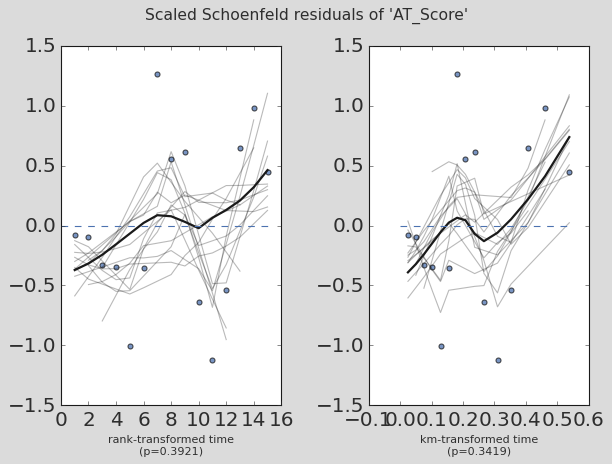

In [442]:
print("\n--- Testing Proportional Hazards Assumption ---")
sub = cox_df_scaled[["AT_Score", duration_col, event_col]].dropna()
cph.check_assumptions(sub, p_value_threshold=0.05, show_plots=True);

## Kaplan Meier Curve

In [444]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.plotting import add_at_risk_counts

In [445]:
threshold = 0.4

required_cols = ["PatientId", "AT_Score", "Clinical_TTP"]
for c in required_cols:
    if c not in bench_df.columns:
        raise ValueError(f"Missing column in bench_df: {c}")

km_df = bench_df[required_cols].copy()
km_df["Event"] = bench_df["Event"].values

# Clean and type-cast
km_df = km_df.dropna(subset=["AT_Score", "Clinical_TTP", "Event"]).copy()
km_df["Clinical_TTP"] = km_df["Clinical_TTP"].astype(float)
km_df["Event"] = km_df["Event"].astype(int)

In [446]:
# Define groups
km_df["AT_group"] = np.where(km_df["AT_Score"] > threshold, f"AT Score > {threshold}", f"AT Score <= {threshold}")

group_A = km_df[km_df["AT_Score"] <= threshold]
group_B = km_df[km_df["AT_Score"] > threshold]

print("Group counts:")
print(km_df["AT_group"].value_counts())
print("\nEvent counts by group:")
print(km_df.groupby("AT_group")["Event"].sum())

Group counts:
AT_group
AT Score <= 0.4    29
AT Score > 0.4     11
Name: count, dtype: int64

Event counts by group:
AT_group
AT Score <= 0.4    7
AT Score > 0.4     8
Name: Event, dtype: int64


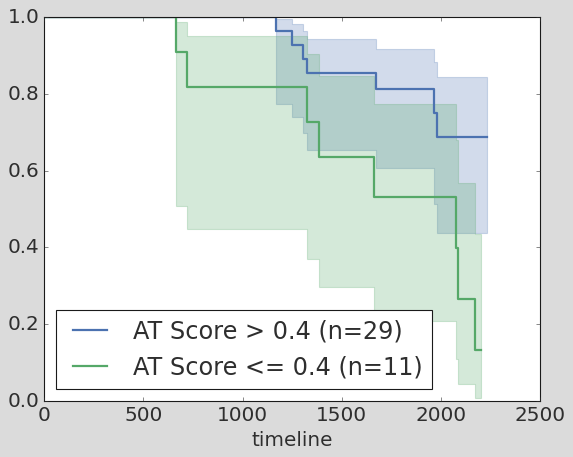

In [447]:
# Fit KM curves
kmf_A = KaplanMeierFitter()
kmf_B = KaplanMeierFitter()

fig, ax = plt.subplots(figsize=(8, 6))

if len(group_A) > 0:
    
    kmf_A.fit(
        durations=group_A["Clinical_TTP"],
        event_observed=group_A["Event"],
        label=f"AT Score > {threshold} (n={len(group_A)})"
    )
    kmf_A.plot_survival_function(ax=ax, ci_show=True, linewidth=2)

if len(group_B) > 0:
    kmf_B.fit(
        durations=group_B["Clinical_TTP"],
        event_observed=group_B["Event"],
        label=f"AT Score <= {threshold} (n={len(group_B)})"
    )
    kmf_B.plot_survival_function(ax=ax, ci_show=True, linewidth=2)


In [448]:
# ------------------------------------------------------------
# Log-rank test (p-value for KM curve separation)
# ------------------------------------------------------------
if len(group_A) > 0 and len(group_B) > 0:
    lr = logrank_test(
        group_A["Clinical_TTP"],
        group_B["Clinical_TTP"],
        event_observed_A=group_A["Event"],
        event_observed_B=group_B["Event"],
    )
    p_value_sep = lr.p_value
    test_stat = lr.test_statistic
    p_text = f"log-rank p = {p_value_sep:.4g}"

    # Explicitly print separation statistics
    print(f"Log-rank test statistic = {test_stat:.4f}")
    print(f"Log-rank p-value (curve separation) = {p_value_sep:.6f}")
else:
    p_value_sep = np.nan
    p_text = "log-rank p = NA (one group empty)"
    print("Log-rank p-value (curve separation) = NA (one group empty)")

Log-rank test statistic = 5.8527
Log-rank p-value (curve separation) = 0.015553
